# 04b · Aşama 4 (devam) — UNCERTAIN kararının çözümlenmesi: "ek inceleme / üst sisteme yönlendirme"
Profesörün planı belirsiz örneklerin otomatik karar yerine **ek incelemeye** veya **üst sisteme** yönlendirilmesini ister.
Bu defter bu adımı somutlaştırır: **UNCERTAIN asla sessiz bir çıkmaz değildir.**

| Basamak | Nerede | Ne olur |
|---|---|---|
| 0 | Cihaz, hemen | UNCERTAIN → geri alınabilir önlem (izleme / hız sınırlama); asla sessizlik, asla otomatik engelleme |
| **2 (ana katkı)** | Cihaz, sonraki akışlar | Ana bilgisayar (host) başına sayaç: W akışlık pencerede p ≤ α+β olan akış sayısı K. K ≥ k\* ise **yükselt**, değilse **serbest bırak** |
| 1 (isteğe bağlı) | Ağ geçidi = "üst sistem" | Yalnızca *bilinen* ailelerle eğitilmiş denetimli model; esas olarak **temel çizgi** olarak raporlanır |

**Operasyonel bütçe (önceden kaydedildi):** cihaz başına haftada en fazla B = 1 yanlış yükseltme. Günde F akış ve W'lik
pencerelerle pencere başına bütçe α_w = B·W/(7F) olur; k\* bu bütçeyle normal-doğrulama pencerelerinden konformal olarak seçilir.

**Dürüstlük notları:**
* TON_IoT sürüm B'de zaman damgası yoktur. Bu nedenle host pencereleri **rastgele çekilir**; gerçek zaman akışı değil, **simülasyondur**.
* Küçük bütçeler için kalibrasyon pencereleri **alt örnekleme** ile üretilir (pencereler örtüşebilir). Bu yüzden garanti yaklaşıktır ve normal-test üzerinde host bazında doğrulanır.
* Görülmeyecek üç aile (ransomware, xss, mitm) daha önce defalarca incelendi. Bu defterin sonuçları **keşif amaçlıdır**; doğrulayıcı test, önceden kaydedilmiş "her seferinde bir aile dışarıda" protokolüyledir (öneri v6, §7a.3).
* `src_ip` yalnızca **gruplama anahtarıdır**, hiçbir zaman model özniteliği değildir.

In [1]:
# ---- Kurulum (her defterde aynı): Drive'ı bağla, ortak kodu içe aktar ----
import os, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
PROJECT_DIR = os.environ.get("TRUSTIDS_PROJECT", "/content/drive/MyDrive/TrustFed-TinyIDS-Final")
QUICK = os.environ.get("TRUSTIDS_QUICK", "0") == "1"   # hızlı mod YALNIZCA kodu test etmek içindir
# Devam modu: Colab oturumu kapanırsa, Drive'a kaydedilmiş tohumlar/adımlar atlanır ve kalan yerden devam edilir.
# Her şeyi baştan hesaplamak için: os.environ["TRUSTIDS_RESUME"] = "0"
RESUME = os.environ.get("TRUSTIDS_RESUME", "1") == "1"
sys.path.insert(0, PROJECT_DIR)

from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from trustids.config import Config
from trustids import utils

# Veri kümesi seçimi: varsayılan TON_IoT; ikinci veri kümesi için TRUSTIDS_CONFIG=edge_iiotset.json
CONFIG_NAME = os.environ.get("TRUSTIDS_CONFIG", "default.json")
CFG_PATH = Path(PROJECT_DIR) / "configs" / CONFIG_NAME
if CONFIG_NAME != "default.json" and not CFG_PATH.exists():
    raise FileNotFoundError(f"{CFG_PATH} bulunamadı: configs/ klasörünü de Drive'a yükleyin.")
cfg = Config.load(CFG_PATH) if CFG_PATH.exists() else Config(project_dir=PROJECT_DIR)
cfg.project_dir = PROJECT_DIR
if QUICK:
    cfg.train_seeds, cfg.validity_resplits, cfg.epochs = cfg.train_seeds[:2], 30, 15
    cfg.random_control_repeats, cfg.bootstrap_repeats = 10, 200
    cfg.lofo_seeds, cfg.fl_orig_rounds = cfg.lofo_seeds[:2], 3
    cfg.resolution_cal_windows, cfg.resolution_eval_windows = 600, 600
cfg.check()
ART = cfg.artifacts
FIG = Path(PROJECT_DIR) / cfg.figures_dir; FIG.mkdir(exist_ok=True)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
print("Proje klasörü:", PROJECT_DIR, "| hızlı mod:", QUICK, "| devam modu:", RESUME)
print("Drive'da kayıtlı ilerleme:", utils.progress(cfg))

Mounted at /content/drive
Proje klasörü: /content/drive/MyDrive/TrustFed-TinyIDS-Final | hızlı mod: False | devam modu: True
Drive'da kayıtlı ilerleme: {'01_hazirlanan_veri': True, '02_tohumlar_tamam': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], '02_oznitelik_karsilastirma_tohumlari': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], '03_kararlar': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], '04b_host_eslesmesi': False}


In [2]:
from trustids import data as D, conformal as C, evaluation as E, resolution as R
P = D.load_prepared(ART / "prepared")
RES_DIR = ART / "resolution"; RES_DIR.mkdir(exist_ok=True)
FP = utils.config_fingerprint(cfg)   # ara sonuç dosyaları bu ayarlara bağlıdır; ayar değişirse yeniden hesaplanır
RUN = utils.new_run_dir(Path(PROJECT_DIR) / cfg.runs_dir, "midterm_phase4b_resolution")
SEEDS = E.available_seeds(cfg)
HOSTMAP = RES_DIR / "host_rows.csv.gz"
if RESUME and HOSTMAP.exists():
    ROWS = pd.read_csv(HOSTMAP, keep_default_na=False)
    ROWS["split"] = ROWS["split"].replace({"": None})
    print("Kayıtlı host eşlemesi kullanılıyor (devam modu)")
else:
    raw = D.load_raw(cfg.data_path, cfg)
    ROWS = R.map_rows(raw, P, cfg)
    ROWS.to_csv(HOSTMAP, index=False)
ROWS = ROWS[ROWS["split"].isin(["benign_val", "benign_test", "dev_test", "heldout_test"])].reset_index(drop=True)
print("eşlenen ham akış:", len(ROWS), ROWS.groupby("split").size().to_dict())
print("farklı host sayısı:", ROWS.groupby("split")["host"].nunique().to_dict())

eşlenen ham akış: 110023 {'benign_test': 8296, 'benign_val': 3328, 'dev_test': 57356, 'heldout_test': 41043}
farklı host sayısı: {'benign_test': 36, 'benign_val': 37, 'dev_test': 10, 'heldout_test': 13}


## Operasyonel bütçe: cihaz başına haftada ≤ 1 yanlış yükseltme

In [3]:
BUD = pd.DataFrame([{"W": W, "günlük_akış_F": F, "pencere_bütçesi_α_w": R.window_budget(cfg.resolution_budget_per_week, W, F),
                     "gereken_kalibrasyon_penceresi": R.min_cal_windows(R.window_budget(cfg.resolution_budget_per_week, W, F))}
                    for W in cfg.resolution_windows for F in cfg.resolution_flows_per_day])
BUD.to_csv(RUN / "04b_operational_budget.csv", index=False); BUD

,W,günlük_akış_F,pencere_bütçesi_α_w,gereken_kalibrasyon_penceresi
0,20,1000,0.002857,349
1,20,5000,0.000571,1749
2,50,1000,0.007143,139
3,50,5000,0.001429,699
4,100,1000,0.014286,69
5,100,5000,0.002857,349


## Basamak 2: host sayacı (tüm tohumlar; her tohum Drive'a kaydedilir, oturum kapanırsa kaldığı yerden devam eder)
Her tohum için: akış p-değerleri → işaret (p ≤ α+β) → pencereler → k\* (normal-doğrulama) → değerlendirme.
Karşılaştırma (ablasyon): yalnızca ANOMALY akışlarını (p ≤ α) sayan sayaç; kendi k\* değeriyle.

In [4]:
def evaluate_seed(seed):
    S = E.load_scores(cfg, seed)
    cal = S[("ae", "benign_cal")]
    pv = {sp: C.pvalues(cal, S[("ae", sp)], seed=seed, model="ae") for sp in ["benign_val", "benign_test", "dev_test", "heldout_test"]}
    p = R.row_values(ROWS, pv)
    flags = {"ANOMALY+UNCERTAIN": p <= cfg.alpha + cfg.beta, "yalnız ANOMALY": p <= cfg.alpha}
    rng = np.random.default_rng(1000 + seed)
    g_val = R.host_groups(ROWS, (ROWS["split"] == "benign_val").to_numpy())
    g_ben = R.host_groups(ROWS, (ROWS["split"] == "benign_test").to_numpy())
    ben_all = np.concatenate(list(g_ben.values()))
    fams = [f for f in cfg.dev_families + cfg.heldout_families if f in set(ROWS["type"])]
    out = []
    for W in cfg.resolution_windows:
        cal_w, _ = R.sample_windows(g_val, W, cfg.resolution_cal_windows, rng)
        ev_w, ev_h = R.sample_windows(g_ben, W, cfg.resolution_eval_windows, rng)
        if len(cal_w) == 0 or len(ev_w) == 0:
            print(f"W={W}: {W} akışa ulaşan normal host yok, atlanıyor"); continue
        for F in cfg.resolution_flows_per_day:
            a_w = R.window_budget(cfg.resolution_budget_per_week, W, F)
            for fname, flag in flags.items():
                k = R.k_threshold(R.counts(flag, cal_w), a_w)
                esc = R.counts(flag, ev_w) >= k
                host_rate = pd.Series(esc).groupby(ev_h).mean()
                base = {"tohum": seed, "W": W, "F": F, "sayaç": fname, "k_yildiz": k, "α_w": a_w,
                        "normal_yanlis_yukseltme_pencere": float(esc.mean()),
                        "normal_haftalik_yanlis_yukseltme_ortalama": R.per_week(float(esc.mean()), W, F),
                        "normal_haftalik_host_p95": R.per_week(float(host_rate.quantile(0.95)), W, F),
                        "normal_haftalik_en_kotu_host": R.per_week(float(host_rate.max()), W, F),
                        "en_kotu_host": str(host_rate.idxmax())}
                for fam in fams:
                    sp = "heldout_test" if fam in cfg.heldout_families else "dev_test"
                    m_f = ((ROWS["split"] == sp) & (ROWS["type"] == fam)).to_numpy()
                    att_ix = np.where(m_f)[0]
                    pure, _ = R.disjoint_windows(R.host_groups(ROWS, m_f), W, rng)
                    row = dict(base, aile=fam, grup="görülmemiş" if fam in cfg.heldout_families else "bilinen",
                               akış_ANOMALY=float(np.mean(p[att_ix] <= cfg.alpha)),
                               akış_UNCERTAIN=float(np.mean((p[att_ix] > cfg.alpha) & (p[att_ix] <= cfg.alpha + cfg.beta))),
                               saf_pencere_sayisi=len(pure),
                               saf_pencere_tespit=float(np.mean(R.counts(flag, pure) >= k)) if len(pure) else np.nan)
                    for rho in cfg.resolution_rho:
                        if len(att_ix) >= W:
                            mw = R.mixed_windows(att_ix, ben_all, W, rho, 300, rng)
                            row[f"karisik_ρ={rho:.2f}"] = float(np.mean(R.counts(flag, mw) >= k))
                    out.append(row)
    # çıkmaz oranı: penceresini dolduramayan hostlardaki UNCERTAIN akışlar (W akışa ulaşmadan karar verilemez)
    unc = (p > cfg.alpha) & (p <= cfg.alpha + cfg.beta)
    sizes = ROWS.groupby(["split", "host", "type"])["host"].transform("size").to_numpy()
    for W in cfg.resolution_windows:
        for grp, msk in [("normal", (ROWS["split"] == "benign_test").to_numpy()),
                         ("bilinen", (ROWS["split"] == "dev_test").to_numpy()),
                         ("görülmemiş", (ROWS["split"] == "heldout_test").to_numpy())]:
            u = unc & msk
            out.append({"tohum": seed, "W": W, "sayaç": "çıkmaz_oranı", "grup": grp,
                        "cikmaz_orani": float(np.mean(sizes[u] < W)) if u.any() else 0.0})
    return pd.DataFrame(out)

for seed in SEEDS:
    f = RES_DIR / f"seed{seed}_{FP}.csv"
    if RESUME and f.exists():
        print("tohum", seed, "Drive'da kayıtlı, atlanıyor (devam modu)"); continue
    evaluate_seed(seed).to_csv(f, index=False)
    print("tohum", seed, "tamam (Drive'a kaydedildi)")
RES = pd.concat([pd.read_csv(RES_DIR / f"seed{s}_{FP}.csv") for s in SEEDS], ignore_index=True)
RES.to_csv(RUN / "04b_resolution_all_seeds.csv", index=False)
print("toplam satır:", len(RES))

tohum 0 tamam (Drive'a kaydedildi)
tohum 1 tamam (Drive'a kaydedildi)
tohum 2 tamam (Drive'a kaydedildi)
tohum 3 tamam (Drive'a kaydedildi)
tohum 4 tamam (Drive'a kaydedildi)
tohum 5 tamam (Drive'a kaydedildi)
tohum 6 tamam (Drive'a kaydedildi)
tohum 7 tamam (Drive'a kaydedildi)
tohum 8 tamam (Drive'a kaydedildi)
tohum 9 tamam (Drive'a kaydedildi)
toplam satır: 1170


## Sonuç 1 — Normal trafikte maliyet: cihaz başına haftalık yanlış yükseltme (hedef ≤ 1)
Ortalama, %95'lik host ve en kötü host ayrı ayrı raporlanır. Bütçe pencereler üzerinden *ortalama* bir garantidir;
tek tek hostlar için değil. En kötü host bu yüzden ayrıca gösterilir.

In [5]:
main = RES[RES["sayaç"] != "çıkmaz_oranı"]
COST = (main.drop_duplicates(["tohum", "W", "F", "sayaç"])
            .groupby(["sayaç", "W", "F"])[["k_yildiz", "normal_haftalik_yanlis_yukseltme_ortalama",
                                           "normal_haftalik_host_p95", "normal_haftalik_en_kotu_host"]]
            .agg(["mean", "std"]).round(3))
COST.columns = [f"{a}_{b}" for a, b in COST.columns]
COST.to_csv(RUN / "04b_benign_cost.csv"); COST

k_yildiz_mean  k_yildiz_std  normal_haftalik_yanlis_yukseltme_ortalama_mean  normal_haftalik_yanlis_yukseltme_ortalama_std  \
sayaç             W   F                                                                                                                                    
ANOMALY+UNCERTAIN 20  1000.0            6.3         0.483                                           3.745                                          8.428   
                      5000.0            8.0         0.667                                          10.745                                         17.182   
                  50  1000.0           10.6         0.699                                           1.812                                          5.729   
                      5000.0           12.4         0.699                                           8.372                                         26.475   
                  100 1000.0           16.6         0.966                                           0.900                                          2.837   
                      5000.0           18.9         1.370                                           4.487                                         14.189   
yalnız ANOMALY    20  1000.0            3.6         0.516                                           0.168                                          0.159   
                      5000.0            4.6         0.516                                           0.070                                          0.148   
                  50  1000.0            4.8         0.919                                           0.193                                          0.206   
                      5000.0            6.0         0.943                                           0.154                                          0.139   
                  100 1000.0            6.9         0.994                                           0.085                                          0.075   
                      5000.0            8.2         1.398                                           0.168                                          0.166   

                              normal_haftalik_host_p95_mean  normal_haftalik_host_p95_std  normal_haftalik_en_kotu_host_mean  normal_haftalik_en_kotu_host_std  
sayaç             W   F                                                                                                                                         
ANOMALY+UNCERTAIN 20  1000.0                         19.264                        54.876                            350.000                             0.000  
                      5000.0                         36.534                       114.236                           1750.000                             0.000  
                  50  1000.0                          1.364                         4.314                             13.642                            43.138  
                      5000.0                          6.304                        19.936                             63.042                           199.357  
                  100 1000.0                          2.811                         8.851                              7.026                            22.127  
                      5000.0                         14.000                        44.272                             35.000                           110.680  
yalnız ANOMALY    20  1000.0                          0.094                         0.198                              1.928                             1.782  
                      5000.0                          0.000                         0.000                              0.874                             1.842  
                  50  1000.0                          0.322                         0.339                              2.270                             2.455  
                      5000.0                          0.352               

## Sonuç 2 — Saldırılar: akış düzeyinde (tek akış) ve host düzeyinde (sayaç) tespit, tohum ortalaması

In [6]:
DET = (main.groupby(["sayaç", "W", "F", "grup", "aile"])
           [["akış_ANOMALY", "akış_UNCERTAIN", "saf_pencere_tespit"] + [c for c in main.columns if c.startswith("karisik_")]]
           .mean().round(3))
DET.to_csv(RUN / "04b_detection_per_family.csv"); DET.xs("ANOMALY+UNCERTAIN", level="sayaç")

akış_ANOMALY  akış_UNCERTAIN  saf_pencere_tespit  karisik_ρ=0.10  karisik_ρ=0.25  karisik_ρ=0.50  karisik_ρ=1.00
W   F      grup       aile                                                                                                                        
20  1000.0 bilinen    backdoor           0.006           0.994               1.000           0.002           0.254           1.000           1.000
                      ddos               0.700           0.258               1.000           0.002           0.214           1.000           1.000
                      dos                0.008           0.914               0.951           0.002           0.194           1.000           1.000
                      injection          0.074           0.101               0.176           0.000           0.000           0.006           0.108
                      password           0.036           0.280               0.579           0.000           0.005           0.069           0.595
                      scanning           0.065           0.922               1.000           0.000           0.238           1.000           1.000
           görülmemiş mitm               0.051           0.389               0.890           0.000           0.009           0.252           0.901
                      ransomware         0.030           0.936               1.000           0.001           0.221           0.990           1.000
                      xss                0.267           0.664               1.000           0.001           0.203           0.999           1.000
    5000.0 bilinen    backdoor           0.006           0.994               1.000           0.000           0.014           1.000           1.000
                      ddos               0.700           0.258               1.000           0.000           0.010           0.989           1.000
                      dos                0.008           0.914               0.950           0.000           0.013           0.953           1.000
                      injection          0.074           0.101               0.063           0.000           0.000           0.000           0.018
                      password           0.036           0.280               0.284           0.000           0.000           0.009           0.291
                      scanning           0.065           0.922               1.000           0.000           0.016           1.000           1.000
           görülmemiş mitm               0.051           0.389               0.698           0.000           0.000           0.051           0.717
                      ransomware         0.030           0.936               1.000           0.000           0.014           0.950           1.000
                      xss                0.267           0.664               1.000           0.000           0.011           0.969           1.000
50  1000.0 bilinen    backdoor           0.006           0.994               1.000           0.007           1.000           1.000           1.000
                      ddos               0.700           0.258               1.000           0.004           0.979           1.000           1.000
                      dos                0.008           0.914               0.956           0.005           0.931           1.000           1.000
                      injection          0.074           0.101               0.362           0.000           0.000           0.013           0.289
                      password           0.036           0.280               0.964           0.000           0.007           0.265           0.949
                      scanning           0.065           0.922               1.000           0.003           0.996           1.000           1.000
           görülmemiş mitm               0.051           0.389               1.000           0.000           0.042           0.727           0.999
                      ransomware         0.030           0.936   

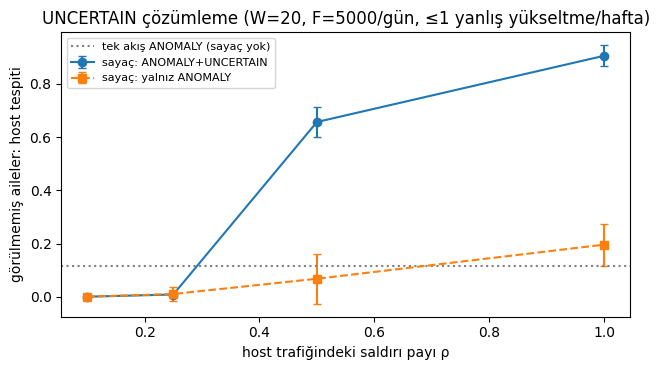

In [7]:
W0, F0 = cfg.resolution_windows[0], max(cfg.resolution_flows_per_day)
sub = main[(main["W"] == W0) & (main["F"] == F0) & (main["grup"] == "görülmemiş")]
rhos = [c for c in sub.columns if c.startswith("karisik_")]
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for fname, mk in [("ANOMALY+UNCERTAIN", "o-"), ("yalnız ANOMALY", "s--")]:
    v = sub[sub["sayaç"] == fname].groupby("tohum")[rhos].mean()
    ax.errorbar([float(c.split("=")[1]) for c in rhos], v.mean(), yerr=v.std(), fmt=mk, capsize=3, label=f"sayaç: {fname}")
flow = sub[sub["sayaç"] == "ANOMALY+UNCERTAIN"].groupby("tohum")["akış_ANOMALY"].mean().mean()
ax.axhline(flow, color="gray", ls=":", label="tek akış ANOMALY (sayaç yok)")
ax.set_xlabel("host trafiğindeki saldırı payı ρ"); ax.set_ylabel("görülmemiş aileler: host tespiti")
ax.set_title(f"UNCERTAIN çözümleme (W={W0}, F={F0}/gün, ≤1 yanlış yükseltme/hafta)")
ax.legend(fontsize=8); fig.tight_layout(); fig.savefig(FIG / "04b_resolution_vs_rho.png", dpi=150)

## Sonuç 3 — Çıkmaz oranı: penceresi dolmadığı için çözümlenemeyen UNCERTAIN akış payı

In [8]:
DEAD = RES[RES["sayaç"] == "çıkmaz_oranı"].groupby(["W", "grup"])["cikmaz_orani"].agg(["mean", "std"]).round(4)
DEAD.to_csv(RUN / "04b_dead_end_rate.csv"); DEAD

mean     std
W   grup                      
20  bilinen     0.0001  0.0001
    görülmemiş  0.0006  0.0002
    normal      0.1283  0.0300
50  bilinen     0.0002  0.0001
    görülmemiş  0.0006  0.0002
    normal      0.2491  0.0556
100 bilinen     0.0002  0.0001
    görülmemiş  0.0006  0.0002
    normal      0.3016  0.0720

## Basamak 1 — "Üst sistem" (ağ geçidi) ve dürüst temel çizgi: yalnızca bilinen ailelerle eğitilmiş Random Forest
Üç soru: (a) RF **tek başına** görülmemiş aileleri ne kadar yakalar (aynı %α yanlış alarmda)? (b) AE'nin UNCERTAIN bandı
içinde RF saldırıyı normalden ayırabiliyor mu (AUC)? (c) AE + ağ geçidi: UNCERTAIN akış, RF eşiği aşarsa ANOMALY olur.
(a) yüksekse bu, TON_IoT'deki "görülmemiş" ailelerin bilinen ailelere benzediği anlamına gelir: bu bir **veri kümesi
bulgusudur** ve gizlenmez.

In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
X, T = P["X"], P["types"]
GW_FILE = RES_DIR / f"gateway_rf_{FP}.csv"
if RESUME and GW_FILE.exists():
    GW = pd.read_csv(GW_FILE); print("Kayıtlı ağ geçidi sonuçları kullanılıyor (devam modu)")
else:
    rows = []
    for seed in SEEDS:
        rf = RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=-1, class_weight="balanced")
        rf.fit(np.r_[X["benign_train"], X["dev_val"]], np.r_[np.zeros(len(X["benign_train"])), np.ones(len(X["dev_val"]))])
        thr = np.quantile(rf.predict_proba(X["benign_cal"])[:, 1], 1 - cfg.alpha, method="higher")
        S = E.load_scores(cfg, seed); cal = S[("ae", "benign_cal")]
        pb = C.pvalues(cal, S[("ae", "benign_test")]); ph = C.pvalues(cal, S[("ae", "heldout_test")])
        rb, rh = rf.predict_proba(X["benign_test"])[:, 1], rf.predict_proba(X["heldout_test"])[:, 1]
        ub = (pb > cfg.alpha) & (pb <= cfg.alpha + cfg.beta)
        for fam in cfg.heldout_families:
            m = T["heldout_test"] == fam
            uh = m & (ph > cfg.alpha) & (ph <= cfg.alpha + cfg.beta)
            auc = roc_auc_score(np.r_[np.zeros(ub.sum()), np.ones(uh.sum())], np.r_[rb[ub], rh[uh]]) if uh.sum() and ub.sum() else np.nan
            rows.append({"tohum": seed, "aile": fam, "AE_ANOMALY": float(np.mean(ph[m] <= cfg.alpha)),
                         "RF_tek_basina_recall": float(np.mean(rh[m] > thr)), "RF_AUC_UNCERTAIN_bandinda": auc,
                         "AE+ağ_geçidi_recall": float(np.mean((ph[m] <= cfg.alpha) | ((ph[m] <= cfg.alpha + cfg.beta) & (rh[m] > thr))))})
        rows.append({"tohum": seed, "aile": "normal (yanlış alarm)", "AE_ANOMALY": float(np.mean(pb <= cfg.alpha)),
                     "RF_tek_basina_recall": float(np.mean(rb > thr)), "RF_AUC_UNCERTAIN_bandinda": np.nan,
                     "AE+ağ_geçidi_recall": float(np.mean((pb <= cfg.alpha) | (ub & (rb > thr))))})
        print("tohum", seed, "tamam")
    GW = pd.DataFrame(rows); GW.to_csv(GW_FILE, index=False)
GWT = GW.groupby("aile").agg(["mean", "std"]).drop(columns="tohum", level=0).round(3)
GWT.to_csv(RUN / "04b_gateway_baseline.csv"); GWT

tohum 0 tamam
tohum 1 tamam
tohum 2 tamam
tohum 3 tamam
tohum 4 tamam
tohum 5 tamam
tohum 6 tamam
tohum 7 tamam
tohum 8 tamam
tohum 9 tamam


AE_ANOMALY        RF_tek_basina_recall        RF_AUC_UNCERTAIN_bandinda        AE+ağ_geçidi_recall       
                            mean    std                 mean    std                      mean    std                mean    std
aile                                                                                                                           
mitm                       0.052  0.005                0.848  0.008                     0.946  0.004               0.367  0.033
normal (yanlış alarm)      0.007  0.001                0.008  0.000                       NaN    NaN               0.010  0.001
ransomware                 0.012  0.006                0.964  0.000                     0.968  0.003               0.967  0.003
xss                        0.518  0.110                0.798  0.112                     0.967  0.007               0.805  0.075

## Özet (profesör için) ve kayıt

In [10]:
import shutil
key = main[(main["sayaç"] == "ANOMALY+UNCERTAIN")]
summary = {
    "not": "Keşif amaçlı; host pencereleri simülasyondur (sürüm B'de zaman damgası yok). Doğrulayıcı test: öneri v6 §7a.3.",
    "operasyonel_bütçe": "cihaz başına haftada <= %.1f yanlış yükseltme" % cfg.resolution_budget_per_week,
    "normal_maliyet": COST.reset_index().to_dict(orient="records"),
    "görülmemiş_host_tespiti": key[key["grup"] == "görülmemiş"].groupby(["W", "F", "aile"])[["akış_ANOMALY", "saf_pencere_tespit"] + rhos].mean().round(3).reset_index().to_dict(orient="records"),
    "çıkmaz_oranı": DEAD.reset_index().to_dict(orient="records"),
    "ağ_geçidi_temel_çizgi": GW.groupby("aile").mean(numeric_only=True).drop(columns="tohum").round(3).reset_index().to_dict(orient="records"),
}
utils.save_json(summary, RUN / "resolution_summary.json")
cfg.save(RUN / "config_used.json"); utils.save_json(utils.environment_info(), RUN / "environment.json")
for f in FIG.glob("04b_*"):
    shutil.copy(f, RUN / f.name)
print("Tüm sonuçlar kaydedildi:", RUN)

Tüm sonuçlar kaydedildi: /content/drive/MyDrive/TrustFed-TinyIDS-Final/runs/20261111-055215_midterm_phase4b_resolution


**Yorumlama kılavuzu.** Ana soru: UNCERTAIN akışlar, normal trafikte haftada ≤ 1 yanlış yükseltme bütçesiyle host düzeyinde
saldırıya dönüştürülebiliyor mu? "yalnız ANOMALY" sayacıyla karşılaştırma, UNCERTAIN seviyesinin katkısını gösterir.
RF temel çizgisi yüksekse bu, veri kümesi hakkında bir bulgudur. Doğrulayıcı sonuçlar ancak "her seferinde bir aile dışarıda"
protokolüyle (yeni tohumlarla) raporlanır.

In [11]:
# Colab: Drive'a yazılan tüm dosyaların kaydedildiğinden emin ol (oturumu kapatmadan önce mutlaka çalıştırın)
print("Kaydedilen ilerleme:", utils.progress(cfg))
if IN_COLAB:
    drive.flush_and_unmount()
    print("Drive kaydedildi ve ayrıldı. Sonraki defter Drive'ı yeniden bağlar.")

Kaydedilen ilerleme: {'01_hazirlanan_veri': True, '02_tohumlar_tamam': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], '02_oznitelik_karsilastirma_tohumlari': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], '03_kararlar': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], '04b_host_eslesmesi': True}
Drive kaydedildi ve ayrıldı. Sonraki defter Drive'ı yeniden bağlar.
